# Náhodná procházka a parciální diferenciální rovnice

*Nad rámec cvičení — oddíly 6.3 a 6.4 skripta.*

---

V sešitu `ch06_markov_linearni_rovnice` jsme náhodnou procházkou řešili soustavu lineárních rovnic. Diskretizovaná parciální diferenciální rovnice **je** soustava lineárních rovnic, takže totéž musí jít i tam. A jde — jen v mnohem hezčí podobě, protože procházka má názorný fyzikální význam.

- **Dirichletova úloha** pro Laplaceovu rovnici: hodnota v bodě = průměr přes okolí
- **procházka po síti**: $u(x) = E\,[\,g(\text{místo, kde procházka opustí oblast})\,]$
- **Poissonova rovnice** se zdrojem: přibude příspěvek nasbíraný po cestě
- **procházka po sférách**: jak se zbavit sítě a být o dva řády rychlejší

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky

## 1. Dirichletova úloha a vlastnost průměru

Hledáme $u$ na oblasti $G$ (vezmeme jednotkový čtverec) splňující

$$\Delta u = 0 \ \text{ uvnitř } G, \qquad u = g \ \text{ na hranici.}$$

Nahradíme-li druhé derivace diferencemi na síti s krokem $h$, dostaneme z pětibodového vzorce

$$\frac{u_{i+1,j} + u_{i-1,j} + u_{i,j+1} + u_{i,j-1} - 4u_{ij}}{h^2} = 0
\qquad\Longleftrightarrow\qquad
u_{ij} = \frac{u_{i+1,j} + u_{i-1,j} + u_{i,j+1} + u_{i,j-1}}{4}.$$

Slovy: **hodnota v uzlu je průměr hodnot ve čtyřech sousedech.** Odtud je ke stochastické interpretaci jediný krok. Průměr přes čtyři sousedy je totiž střední hodnota přes náhodně vybraného souseda:

$$u(x) = E\big[\,u(\text{náhodný soused})\,\big].$$

Opakujeme-li úvahu, dostaneme po $k$ krocích $u(x) = E[u(X_k)]$ pro náhodnou procházku $X_k$. Jakmile procházka narazí na hranici, hodnotu známe — je to $g$. Takže

$$\boxed{\,u(x) = E\big[\,g(X_T)\,\big]\,}$$

kde $T$ je okamžik prvního dosažení hranice. Řešení v bodě $x$ je **střední hodnota okrajové podmínky v místě, kde náhodná procházka z $x$ opustí oblast.**

### Jak to ověřit

Potřebujeme úlohu se známým řešením. Funkce $u(x,y) = x^2 - y^2$ je harmonická ($\Delta u = 2 - 2 = 0$), a navíc je na ní pětibodový vzorec **přesný** — chyba diskretizace je nulová, protože čtvrté derivace jsou nulové. Položíme tedy $g = u$ na hranici a uvnitř musí vyjít totéž.

In [2]:
def g_harmonicka(x, y):
    """Okrajová podmínka z harmonické funkce u = x² - y²."""
    return x * x - y * y


def prochazka_po_siti(x0, y0, h, g, f=None, N=20_000):
    """u(x0,y0) jako střední hodnota g v místě opuštění čtverce.

    f != None řeší Poissonovu rovnici Δu = f: po cestě se sbírá -h²f/4 za každý krok.
    Vrací (odhad, směrodatná chyba, průměrný počet kroků).
    """
    s = s2 = 0.0
    kroku_celkem = 0
    for _ in range(N):
        x, y, acc, kroku = x0, y0, 0.0, 0
        while 0 < x < 1 and 0 < y < 1:
            if f is not None:
                acc -= h * h * f(x, y) / 4.0
            smer = random.randrange(4)
            if smer == 0:
                x += h
            elif smer == 1:
                x -= h
            elif smer == 2:
                y += h
            else:
                y -= h
            x, y = round(x, 9), round(y, 9)
            kroku += 1
        v = acc + g(x, y)
        s += v
        s2 += v * v
        kroku_celkem += kroku
    m = s / N
    return m, math.sqrt(max(s2 / N - m * m, 0.0) / N), kroku_celkem / N


h = 1 / 40
print(f"Laplaceova rovnice, síť h = 1/{round(1/h)}")
print(f"{'bod':>14s} {'procházka':>22s} {'přesně':>10s} {'kroků':>8s}")
for px, py in ((0.5, 0.5), (0.25, 0.75), (0.1, 0.5), (0.5, 0.9)):
    m, se, kroku = prochazka_po_siti(px, py, h, g_harmonicka)
    print(f"({px:.2f}, {py:.2f}) {m:>14.5f} +- {se:<6.5f} {g_harmonicka(px, py):>10.5f} {kroku:>8.0f}")
    assert abs(m - g_harmonicka(px, py)) < 5 * se

Laplaceova rovnice, síť h = 1/40
           bod              procházka     přesně    kroků
(0.50, 0.50)       -0.00059 +- 0.00411    0.00000      467
(0.25, 0.75)       -0.49702 +- 0.00336   -0.50000      292
(0.10, 0.50)       -0.23923 +- 0.00222   -0.24000      186
(0.50, 0.90)       -0.55600 +- 0.00308   -0.56000      190


Sedí to všude. Všimněte si posledního sloupce: procházka z bodu uprostřed čtverce udělá při $h = 1/40$ kolem tisícovky kroků, zatímco z bodu blízko kraje jen pár desítek. To dává smysl — a zároveň napovídá, kde bude metoda drahá.

## 2. Co ta procházka vlastně vidí

Nakreslíme několik procházek a rozdělení míst, kde končí. Právě tohle rozdělení (říká se mu **harmonická míra**) určuje, kolik která část hranice do výsledku přispěje.

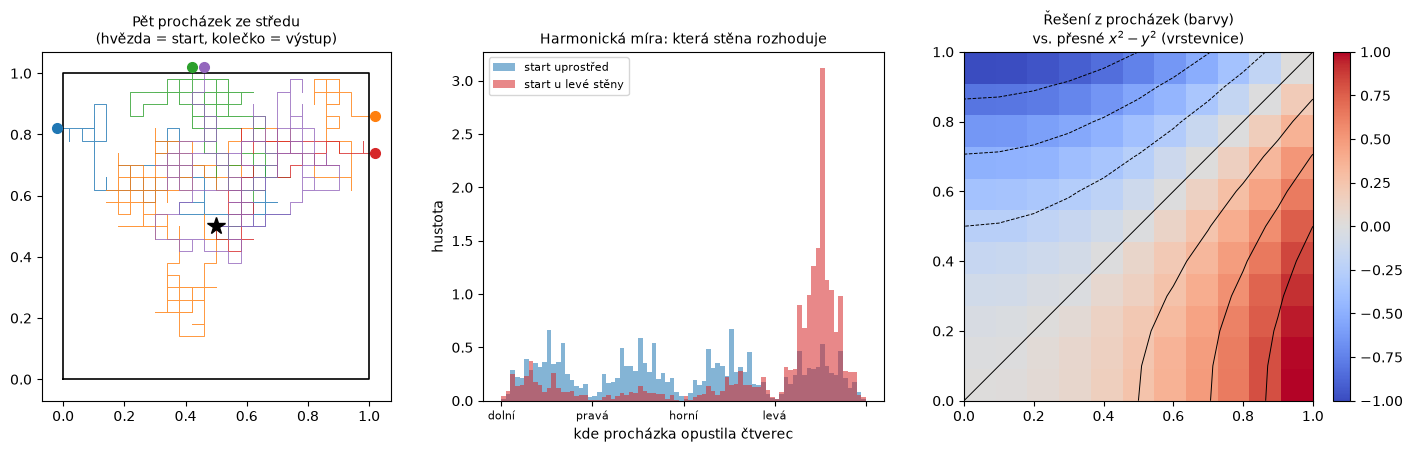

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.5))

# vlevo: pár procházek
ax = axes[0]
h_obr = 1 / 25
for barva in ("tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"):
    x, y = 0.5, 0.5
    cesta = [(x, y)]
    while 0 < x < 1 and 0 < y < 1:
        smer = random.randrange(4)
        x += h_obr * (1 if smer == 0 else -1 if smer == 1 else 0)
        y += h_obr * (1 if smer == 2 else -1 if smer == 3 else 0)
        x, y = round(x, 9), round(y, 9)
        cesta.append((x, y))
    ax.plot(*zip(*cesta), lw=0.7, alpha=0.8, color=barva)
    ax.plot([cesta[-1][0]], [cesta[-1][1]], "o", ms=7, color=barva,
            clip_on=False, zorder=5)          # výstup leží na hranici, jinak by se půlka ořízla
ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], "k", lw=1.2)
ax.plot([0.5], [0.5], "k*", ms=13, zorder=6)
ax.set_xlim(-0.07, 1.07); ax.set_ylim(-0.07, 1.07)
ax.set_aspect("equal")
ax.set_title("Pět procházek ze středu\n(hvězda = start, kolečko = výstup)", fontsize=10)

# uprostřed: kde procházky vystupují
ax = axes[1]
for (sx, sy), barva, nazev in (((0.5, 0.5), "tab:blue", "start uprostřed"),
                               ((0.15, 0.5), "tab:red", "start u levé stěny")):
    uhly = []
    for _ in range(4000):
        x, y = sx, sy
        while 0 < x < 1 and 0 < y < 1:
            smer = random.randrange(4)
            x += h_obr * (1 if smer == 0 else -1 if smer == 1 else 0)
            y += h_obr * (1 if smer == 2 else -1 if smer == 3 else 0)
            x, y = round(x, 9), round(y, 9)
        # obvodová souřadnice 0..4 po obvodu čtverce
        if y <= 0:
            s_ = x
        elif x >= 1:
            s_ = 1 + y
        elif y >= 1:
            s_ = 2 + (1 - x)
        else:
            s_ = 3 + (1 - y)
        uhly.append(s_)
    ax.hist(uhly, bins=80, range=(0, 4), density=True, alpha=0.55, color=barva, label=nazev)
ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels(["dolní", "pravá", "horní", "levá", ""], fontsize=8)
ax.set_xlabel("kde procházka opustila čtverec")
ax.set_ylabel("hustota")
ax.set_title("Harmonická míra: která stěna rozhoduje", fontsize=10)
ax.legend(fontsize=8)

# vpravo: celé řešení na hrubé síti
ax = axes[2]
m_sit = 11
h_sit = 1 / (m_sit - 1)
pole = [[0.0] * m_sit for _ in range(m_sit)]
for i in range(m_sit):
    for j in range(m_sit):
        x, y = i * h_sit, j * h_sit
        if i in (0, m_sit - 1) or j in (0, m_sit - 1):
            pole[j][i] = g_harmonicka(x, y)
        else:
            pole[j][i] = prochazka_po_siti(x, y, h_sit, g_harmonicka, N=4000)[0]
im = ax.imshow(pole, origin="lower", extent=(0, 1, 0, 1), cmap="coolwarm")
plt.colorbar(im, ax=ax, fraction=0.046)
ax.contour(
    [i * h_sit for i in range(m_sit)], [j * h_sit for j in range(m_sit)],
    [[g_harmonicka(i * h_sit, j * h_sit) for i in range(m_sit)] for j in range(m_sit)],
    levels=8, colors="k", linewidths=0.7)
ax.set_title("Řešení z procházek (barvy)\nvs. přesné $x^2-y^2$ (vrstevnice)", fontsize=10)

plt.tight_layout()
plt.show()

Pravý obrázek je celé řešení poskládané z nezávislých procházek v každém uzlu — barvy sedí na vrstevnice přesného řešení.

Zároveň je na něm vidět **hlavní slabina**: museli jsme pustit procházky zvlášť v každém z 81 vnitřních uzlů. Chceme-li celé řešení na jemné síti, je relaxační metoda nesrovnatelně lepší. Procházka se vyplatí, když chcete **hodnotu v jednom bodě** (nebo v pár bodech) — přesně jako u soustav rovnic.

## 3. Poissonova rovnice

Se zdrojem na pravé straně,

$$\Delta u = f \ \text{ v } G, \qquad u = g \ \text{ na } \partial G,$$

se diskrétní vztah změní na

$$u_{ij} = \frac{1}{4}\sum_{\text{sousedé}} u - \frac{h^2}{4}f_{ij},$$

takže procházka kromě koncové hodnoty $g$ **sbírá příspěvek $-\tfrac{h^2}{4}f$ v každém navštíveném uzlu**:

$$u(x) = E\Big[\,g(X_T) - \frac{h^2}{4}\sum_{k=0}^{T-1} f(X_k)\,\Big].$$

Fyzikálně: okrajová podmínka je to, co přiteče zvenčí, a suma po cestě je to, co se cestou vyrobí.

Kontrola: $u = x^2 + y^2$ dává $\Delta u = 4$, takže volíme $f \equiv 4$.

In [4]:
def g_poisson(x, y):
    return x * x + y * y


print("Poissonova rovnice Δu = 4, u = x² + y² na hranici")
print(f"{'bod':>14s} {'procházka':>22s} {'přesně':>10s}")
for px, py in ((0.5, 0.5), (0.25, 0.75), (0.1, 0.2)):
    m, se, _ = prochazka_po_siti(px, py, h, g_poisson, f=lambda x, y: 4.0)
    print(f"({px:.2f}, {py:.2f}) {m:>14.5f} +- {se:<6.5f} {g_poisson(px, py):>10.5f}")
    assert abs(m - g_poisson(px, py)) < 5 * se

Poissonova rovnice Δu = 4, u = x² + y² na hranici
           bod              procházka     přesně
(0.50, 0.50)        0.50043 +- 0.00410    0.50000
(0.25, 0.75)        0.62744 +- 0.00333    0.62500
(0.10, 0.20)        0.04844 +- 0.00145    0.05000


## 4. Procházka po sférách

Procházka po síti má dvě nepříjemnosti: potřebuje síť (a ta zavádí chybu diskretizace), a počet kroků roste jako $1/h^2$ — zjemnění sítě na polovinu znamená čtyřnásobek práce.

**Procházka po sférách** (Muller, 1956) obojí obchází a stojí na jednoduchém faktu:

> Je-li $u$ harmonická v kouli se středem $x$, pak $u(x)$ je průměr $u$ po povrchu té koule.

Takže místo krůčku k sousedovi můžeme **skočit rovnou na náhodný bod největší koule, která se do oblasti vejde** — a střední hodnota se nezmění. Algoritmus:

1. V bodě $x$ najdi $r = \mathrm{dist}(x, \partial G)$.
2. Skoč na rovnoměrně náhodný bod sféry o poloměru $r$ (cvičení 8).
3. Opakuj, dokud $r > \varepsilon$; pak vezmi nejbližší bod hranice a vrať $g$ tam.

Žádná síť, a kroků je potřeba jen $O(\log(1/\varepsilon))$ místo $O(1/h^2)$, protože každý skok zmenší vzdálenost od hranice v průměru o konstantní faktor.

In [5]:
def vzdalenost_od_hranice(x, y):
    return min(x, 1 - x, y, 1 - y)


def nejblizsi_na_hranici(x, y):
    kandidati = ((x, 0.0, y), (x, 1.0, 1 - y), (0.0, y, x), (1.0, y, 1 - x))
    bx, by, _ = min(kandidati, key=lambda t: t[2])
    return bx, by


def prochazka_po_sferach(x0, y0, g, N=20_000, eps=1e-3):
    """Procházka po sférách (zde kružnicích) pro Laplaceovu rovnici."""
    s = s2 = 0.0
    skoku_celkem = 0
    for _ in range(N):
        x, y, skoku = x0, y0, 0
        while True:
            r = vzdalenost_od_hranice(x, y)
            if r < eps:
                break
            uhel = 2 * math.pi * random.random()
            x += r * math.cos(uhel)
            y += r * math.sin(uhel)
            skoku += 1
        v = g(*nejblizsi_na_hranici(x, y))
        s += v
        s2 += v * v
        skoku_celkem += skoku
    m = s / N
    return m, math.sqrt(max(s2 / N - m * m, 0.0) / N), skoku_celkem / N


import time

print(f"{'bod':>14s} {'metoda':>12s} {'odhad':>21s} {'přesně':>9s} {'kroků':>8s} {'čas':>8s}")
for px, py in ((0.5, 0.5), (0.25, 0.75)):
    t0 = time.perf_counter()
    m1, se1, k1 = prochazka_po_siti(px, py, h, g_harmonicka, N=20_000)
    t1 = time.perf_counter() - t0
    t0 = time.perf_counter()
    m2, se2, k2 = prochazka_po_sferach(px, py, g_harmonicka, N=20_000)
    t2 = time.perf_counter() - t0
    pres = g_harmonicka(px, py)
    print(f"({px:.2f}, {py:.2f}) {'po síti':>12s} {m1:>13.5f} +- {se1:<5.5f} {pres:>9.5f} {k1:>8.0f} {t1:>7.2f} s")
    print(f"{'':>14s} {'po sférách':>12s} {m2:>13.5f} +- {se2:<5.5f} {pres:>9.5f} {k2:>8.1f} {t2:>7.2f} s")
    print(f"{'':>14s} {'zrychlení':>12s} {t1 / t2:>13.0f}x")

           bod       metoda                 odhad    přesně    kroků      čas
(0.50, 0.50)      po síti      -0.00212 +- 0.00410   0.00000      473    6.49 s
                 po sférách       0.00029 +- 0.00414   0.00000      7.8    0.05 s
                  zrychlení           133x
(0.25, 0.75)      po síti      -0.49959 +- 0.00334  -0.50000      289    4.17 s
                 po sférách      -0.50098 +- 0.00334  -0.50000      8.5    0.06 s
                  zrychlení            68x


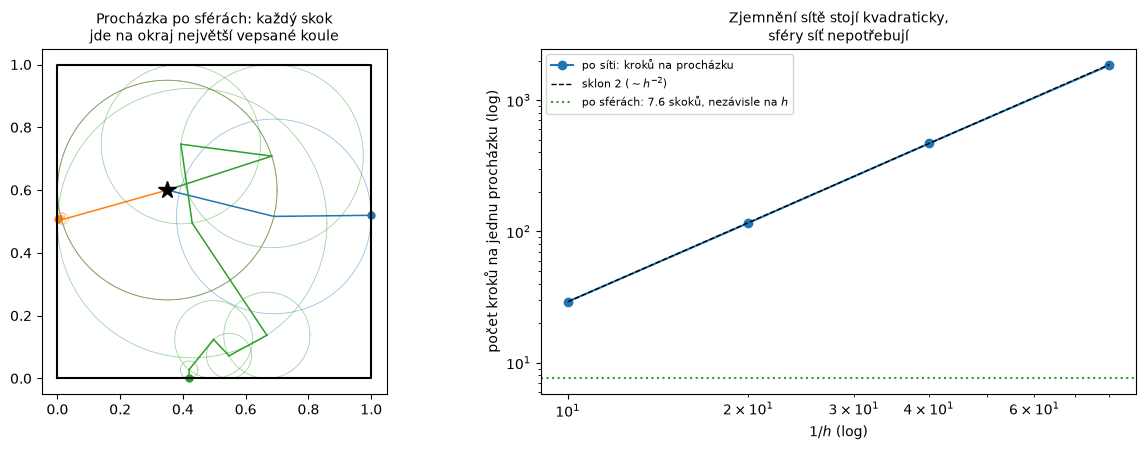

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

ax = axes[0]
for barva in ("tab:blue", "tab:orange", "tab:green"):
    x, y = 0.35, 0.6
    for _ in range(12):
        r = vzdalenost_od_hranice(x, y)
        if r < 1e-3:
            break
        kruh = [(x + r * math.cos(2 * math.pi * t / 100), y + r * math.sin(2 * math.pi * t / 100))
                for t in range(101)]
        ax.plot(*zip(*kruh), lw=0.6, color=barva, alpha=0.45)
        uhel = 2 * math.pi * random.random()
        nx, ny = x + r * math.cos(uhel), y + r * math.sin(uhel)
        ax.plot([x, nx], [y, ny], "-", lw=1.1, color=barva)
        x, y = nx, ny
    ax.plot([x], [y], "o", ms=5, color=barva)
ax.plot([0.35], [0.6], "k*", ms=13)
ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], "k", lw=1.5)
ax.set_aspect("equal")
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)
ax.set_title("Procházka po sférách: každý skok\njde na okraj největší vepsané koule", fontsize=10)

ax = axes[1]
hs = [1 / 10, 1 / 20, 1 / 40, 1 / 80]
kroky_sit, casy_sit = [], []
for hh in hs:
    t0 = time.perf_counter()
    _, _, k = prochazka_po_siti(0.5, 0.5, hh, g_harmonicka, N=1500)
    casy_sit.append((time.perf_counter() - t0) / 1500)
    kroky_sit.append(k)
_, _, k_sf = prochazka_po_sferach(0.5, 0.5, g_harmonicka, N=1500)
t0 = time.perf_counter()
prochazka_po_sferach(0.5, 0.5, g_harmonicka, N=1500)
cas_sf = (time.perf_counter() - t0) / 1500

ax.loglog([1 / hh for hh in hs], kroky_sit, "o-", label="po síti: kroků na procházku")
ax.loglog([1 / hh for hh in hs], [kroky_sit[0] * (1 / hh / (1 / hs[0])) ** 2 for hh in hs], "k--",
          lw=1, label="sklon 2 ($\\sim h^{-2}$)")
ax.axhline(k_sf, color="tab:green", ls=":", label=f"po sférách: {k_sf:.1f} skoků, nezávisle na $h$")
ax.set_xlabel("$1/h$ (log)")
ax.set_ylabel("počet kroků na jednu procházku (log)")
ax.set_title("Zjemnění sítě stojí kvadraticky,\nsféry síť nepotřebují", fontsize=10)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Pravý graf shrnuje rozdíl: na síti roste cena jako $h^{-2}$, u sfér je konstantní — a navíc mnohem menší. V naší úloze je procházka po sférách o dva řády rychlejší a nemá chybu diskretizace.

Cenou je, že potřebujeme umět spočítat **vzdálenost od hranice**. Pro čtverec je to triviální, pro složitou oblast už ne — a tam může být síť jednodušší.

## Shrnutí

| Pojem | Co si pamatovat |
|-------|-----------------|
| Vlastnost průměru | $u_{ij}$ = průměr čtyř sousedů ⟺ $\Delta u = 0$ diskrétně |
| Dirichletova úloha | $u(x) = E[\,g(X_T)\,]$, kde $X_T$ je místo opuštění oblasti |
| Harmonická míra | rozdělení výstupního bodu; určuje, která část hranice rozhoduje |
| Poissonova rovnice | $u(x) = E\big[g(X_T) - \tfrac{h^2}{4}\sum_k f(X_k)\big]$ — sbírá se po cestě |
| Cena na síti | $O(h^{-2})$ kroků na procházku; zjemnění je drahé |
| Procházka po sférách | skok na okraj největší vepsané koule; $O(\log 1/\varepsilon)$ skoků, bez sítě |
| Kdy se vyplatí | hodnota v **jednom bodě** složité nebo vysokorozměrné oblasti |
| Kdy ne | celé řešení na jemné síti — tam vyhraje relaxace nebo konečné prvky |

Hlavní myšlenka je stejná jako u soustav rovnic: klasické metody spočítají **všechno**, náhodná procházka jde **rovnou pro to, co chcete**. V nízké dimenzi je to plýtvání, ve vysoké je to jediná schůdná cesta — a tady se kruh uzavírá s `ch01_05_kdy_se_mc_vyplati`.

### Zkuste si

1. Vezměte jinou harmonickou funkci, třeba $u = e^x\sin y$, a ověřte obě metody. Proč je teď chyba diskretizace na síti nenulová?
2. Změřte, jak roste počet skoků u procházky po sférách s $\varepsilon$. Sedí $O(\log 1/\varepsilon)$?
3. Řešte úlohu na oblasti ve tvaru L (čtverec s vyříznutým rohem). Co se stane s procházkou po sférách u vnitřního rohu?
4. Rozšiřte procházku po síti do tří rozměrů a změřte, jak roste počet kroků. Jak si vede proti relaxaci v 3D?
5. Pro Poissonovu rovnici zkuste nekonstantní $f(x,y) = \sin(\pi x)\sin(\pi y)$ a porovnejte s analytickým řešením.
6. Spočítejte řešení v jednom bodě na síti $h = 1/200$ oběma metodami a porovnejte čas při stejné výsledné přesnosti.